In [1]:
import pandas as pd
import numpy as np

In [2]:
FAO_FILE = r"..\data\processed\fao_syria_yield.csv"
NASA_FILE = r"..\data\processed\nasa_syria_climate.csv"

# fao

## check loaded data

In [3]:
fao_df = pd.read_csv(FAO_FILE)

In [4]:
fao_df.sample(10)

,country,crop,crop_code,element,year,unit,yield_hg_ha,flag
372,Syrian Arab Republic,Sorghum,114,Yield,2023,kg/ha,1190.8,A
168,Syrian Arab Republic,"Lentils, dry",1704,Yield,2023,kg/ha,833.1,A
172,Syrian Arab Republic,Maize (corn),112,Yield,1993,kg/ha,3615.7,A
340,Syrian Arab Republic,Sorghum,114,Yield,1991,kg/ha,808.7,A
301,Syrian Arab Republic,Rice,113,Yield,1992,kg/ha,7421.1,E
119,Syrian Arab Republic,Grapes,1330,Yield,2008,kg/ha,5135.3,A
148,Syrian Arab Republic,"Lentils, dry",1704,Yield,2003,kg/ha,1213.1,A
363,Syrian Arab Republic,Sorghum,114,Yield,2014,kg/ha,2580.2,A
33,Syrian Arab Republic,Apples,1341,Yield,2024,kg/ha,3842.9,A
419,Syrian Arab Republic,Sunflower seed,1445,Yield,2004,kg/ha,1667.6,A


In [5]:
fao_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 508 entries, 0 to 507
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      508 non-null    object 
 1   crop         508 non-null    object 
 2   crop_code    508 non-null    int64  
 3   element      508 non-null    object 
 4   year         508 non-null    int64  
 5   unit         508 non-null    object 
 6   yield_hg_ha  508 non-null    float64
 7   flag         508 non-null    object 
dtypes: float64(1), int64(2), object(5)
memory usage: 31.9+ KB


In [6]:
len(fao_df['crop'].unique()), fao_df['crop'].unique()

(16,
 array(['Apples', 'Barley', 'Chick peas, dry', 'Grapes', 'Lentils, dry',
        'Maize (corn)', 'Oats', 'Olives', 'Potatoes', 'Rice',
        'Sesame seed', 'Sorghum', 'Sugar beet', 'Sunflower seed',
        'Tomatoes', 'Wheat'], dtype=object))

In [12]:
len(fao_df['flag'].unique()), fao_df['flag'].unique()

(2, array(['A', 'E'], dtype=object))

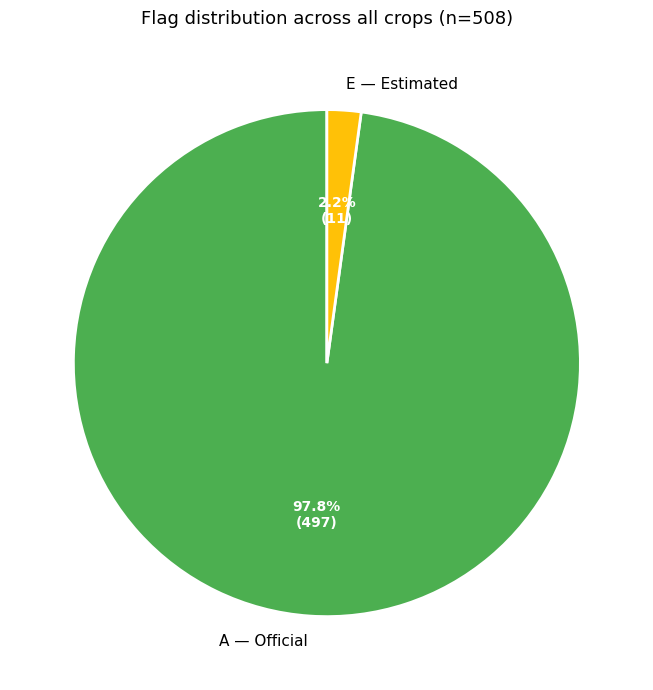

Flag counts:
flag
A    497
E     11

Percentages:
flag
A   97.8
E    2.2


In [17]:
import matplotlib.pyplot as plt

# Flag labels (add meanings in the legend so the plot is self-documenting)
FLAG_MEANING = {
    "A": "A — Official",
    "E": "E — Estimated",
    "I": "I — Imputed",
}

counts = fao_df["flag"].value_counts().sort_index()   # A, E, I order
labels = [FLAG_MEANING.get(f, f) for f in counts.index]
colors = {"A": "#4CAF50", "E": "#FFC107", "I": "#F44336"}
pie_colors = [colors.get(f, "gray") for f in counts.index]

fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    counts.values,
    labels=labels,
    autopct=lambda p: f"{p:.1f}%\n({int(round(p * counts.sum() / 100))})",
    startangle=90,
    colors=pie_colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11},
)

for t in autotexts:
    t.set_fontsize(10)
    t.set_fontweight("bold")
    t.set_color("white")

ax.set_title(f"Flag distribution across all crops (n={counts.sum()})",
             fontsize=13, pad=16)
plt.tight_layout()
plt.show()

print("Flag counts:")
print(counts.to_string())
print(f"\nPercentages:")
print((counts / counts.sum() * 100).round(2).to_string())

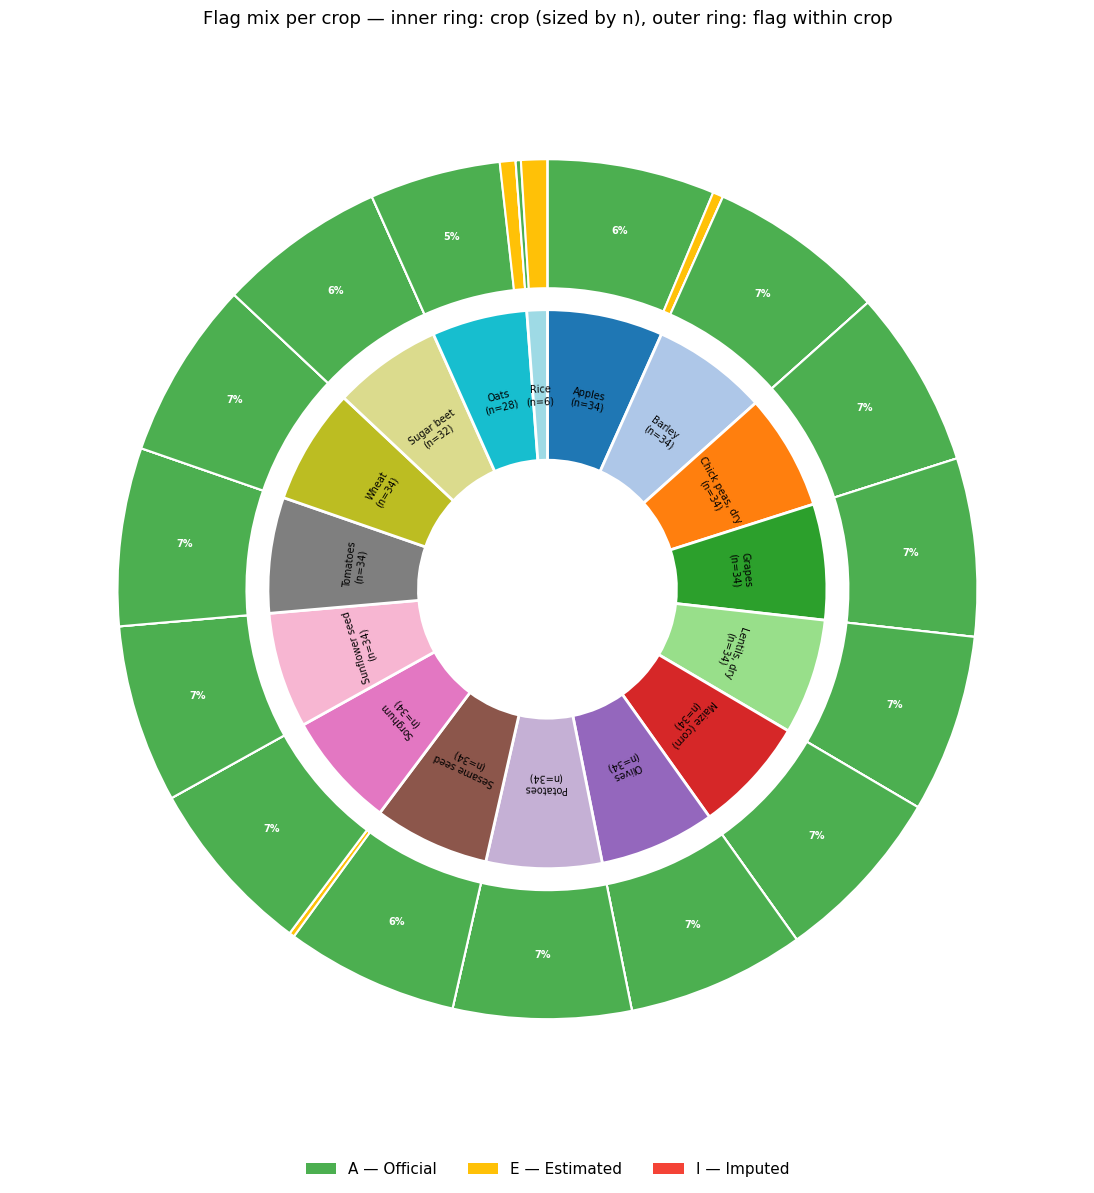

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ── Prepare the data ────────────────────────────────────────
# Count of (crop, flag) pairs, ordered A → E → I inside each crop
flag_order  = ["A", "E", "I"]
flag_colors = {"A": "#4CAF50", "E": "#FFC107", "I": "#F44336"}

pivot = (
    fao_df.pivot_table(index="crop", columns="flag",
                    values="yield_hg_ha", aggfunc="count", fill_value=0)
      .reindex(columns=flag_order, fill_value=0)
)
pivot["total"] = pivot.sum(axis=1)
pivot = pivot.sort_values("total", ascending=False)   # largest crops first

# Inner ring sizes = total rows per crop
inner_sizes  = pivot["total"].values
inner_labels = pivot.index.tolist()

# Outer ring sizes = (crop, flag) row counts, preserving crop order
outer_sizes  = pivot[flag_order].values.flatten()
outer_colors = [flag_colors[f] for f in flag_order] * len(pivot)

# ── Draw ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 12))

# Inner ring: crops
inner_wedges, _ = ax.pie(
    inner_sizes,
    radius=0.65,
    colors=plt.cm.tab20(np.linspace(0, 1, len(inner_sizes))),
    wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.35},
    startangle=90,
    counterclock=False,
)

# Outer ring: flags, aligned angularly with inner ring
outer_wedges, _ = ax.pie(
    outer_sizes,
    radius=1.0,
    colors=outer_colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5, "width": 0.30},
    startangle=90,
    counterclock=False,
)

# ── Labels on the inner ring (crop names, radial placement) ─
for wedge, label, count in zip(inner_wedges, inner_labels, inner_sizes):
    angle = (wedge.theta2 + wedge.theta1) / 2
    x = 0.45 * np.cos(np.deg2rad(angle))
    y = 0.45 * np.sin(np.deg2rad(angle))
    # Rotate label to be readable
    rotation = angle - 90 if angle < 90 or angle > 270 else angle + 90
    ax.text(x, y, f"{label}\n(n={count})",
            ha="center", va="center",
            fontsize=7, rotation=rotation,
            rotation_mode="anchor")

# ── Percentage labels on the outer ring ────────────────────
for wedge, size in zip(outer_wedges, outer_sizes):
    if size == 0:
        continue
    angle = (wedge.theta2 + wedge.theta1) / 2
    pct = 100 * size / outer_sizes.sum()
    if pct < 1.5:      # skip tiny slices to avoid clutter
        continue
    x = 0.85 * np.cos(np.deg2rad(angle))
    y = 0.85 * np.sin(np.deg2rad(angle))
    ax.text(x, y, f"{pct:.0f}%",
            ha="center", va="center",
            fontsize=7, color="white", fontweight="bold")

# ── Legend ─────────────────────────────────────────────────
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=flag_colors["A"], label="A — Official"),
    Patch(facecolor=flag_colors["E"], label="E — Estimated"),
    Patch(facecolor=flag_colors["I"], label="I — Imputed"),
]
ax.legend(handles=legend_handles,
          loc="upper center", bbox_to_anchor=(0.5, -0.02),
          ncol=3, fontsize=11, frameon=False)

ax.set_title(
    "Flag mix per crop — inner ring: crop (sized by n), outer ring: flag within crop",
    fontsize=13, pad=20,
)
ax.set(aspect="equal")
plt.tight_layout()
plt.show()

A — Official Value
This is the most trustworthy flag. It means the data point was reported directly by a national source (like a government ministry or official questionnaire) and is considered an observed statistic . For your modeling, these rows represent the "ground truth" of Syrian crop yields.

E — Estimated Value
This means FAO calculated the number because a direct official figure wasn't available. It could be derived from related data (like calculating yield from production and area) or based on assumptions . While still based on real data, it introduces a layer of calculation. In your EDA, a crop with a high percentage of E flags might show a smoother or less erratic trend than reality.

I — Imputed Value
This is the most important flag to watch. It means the value is fabricated by FAO to fill a gap in the time series . Common methods include carrying the last known value forward or drawing a straight line between two existing data points . For machine learning, this is dangerous: the model might learn the imputation pattern (e.g., "yield is always the same as last year") rather than the actual relationship between climate and crops.

In [ ]:
"Year range:", fao_df['year'].min(), "to", fao_df['year'].max()

('Year range:', np.int64(1991), '→', np.int64(2024))

In [ ]:
fao_df['year'] = pd.to_datetime(fao_df["year"].astype(int).astype(str), format="%Y")
"Year range:", fao_df['year'].min(), "to", fao_df['year'].max()

('Year range:',
 Timestamp('1991-01-01 00:00:00'),
 '→',
 Timestamp('2024-01-01 00:00:00'))

In [10]:
fao_df.describe()

,crop_code,year,yield_hg_ha
count,508.000000,508,508.000000
mean,1032.338583,2007-03-20 11:28:49.133858048,9275.218504
min,111.000000,1991-01-01 00:00:00,150.100000
25%,115.000000,1999-01-01 00:00:00,882.075000
50%,1341.000000,2007-01-01 00:00:00,1789.550000
75%,1510.000000,2016-01-01 00:00:00,6511.650000
max,1801.000000,2024-01-01 00:00:00,76775.600000
std,667.487541,NaN,15945.179149


- convert 'year' column to datetime type
- train on A — Official Value flag only
- drop crops with null values

## Per-crop histogram

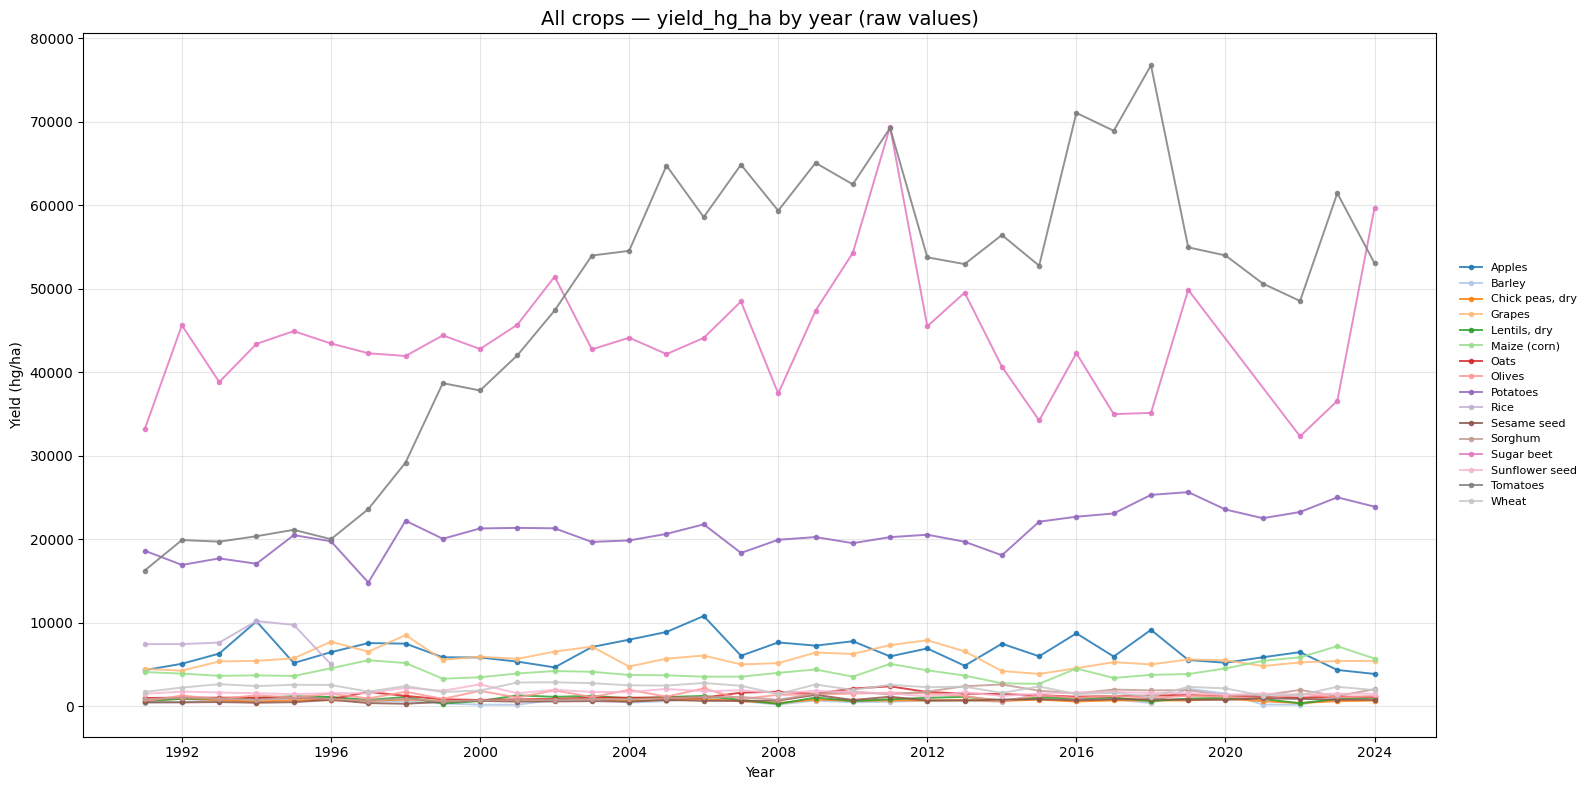

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TARGET = "yield_hg_ha"
crops_list = sorted(fao_df["crop"].unique())

fig, ax = plt.subplots(figsize=(16, 8))

# Use a distinct color per crop
cmap = plt.get_cmap("tab20")
for i, crop in enumerate(crops_list):
    sub = fao_df[fao_df["crop"] == crop].sort_values("year")
    ax.plot(sub["year"], sub[TARGET],
            marker="o", markersize=3, linewidth=1.4,
            color=cmap(i % 20), label=crop, alpha=0.85)

ax.set_title(f"All crops — {TARGET} by year (raw values)", fontsize=14)
ax.set_xlabel("Year")
ax.set_ylabel("Yield (hg/ha)")
ax.grid(True, alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5),
          fontsize=8, ncol=1, frameon=False)
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd
import numpy as np

TARGET = "yield_hg_ha"

# ── Build the per-crop statistics table ─────────────────────
stats = (
    fao_df.groupby("crop")[TARGET]
      .agg(
          n         = "count",
          min       = "min",
          p05       = lambda s: s.quantile(0.05),
          p25       = lambda s: s.quantile(0.25),
          median    = "median",
          mean      = "mean",
          p75       = lambda s: s.quantile(0.75),
          p95       = lambda s: s.quantile(0.95),
          max       = "max",
          std       = "std",
      )
      .assign(
          cv        = lambda d: d["std"] / d["mean"],                    # coefficient of variation
          range_x   = lambda d: d["max"] / d["min"].replace(0, np.nan),  # dynamic range (max/min)
          iqr       = lambda d: d["p75"] - d["p25"],                     # interquartile range
      )
      .sort_values("mean", ascending=False)
)

# ── Also pull year coverage per crop ────────────────────────
years_per_crop = (
    fao_df.groupby("crop")["year"]
      .agg(year_min="min", year_max="max", n_years="nunique")
)
stats = stats.join(years_per_crop)

# ── Pretty-print ────────────────────────────────────────────
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

print("=" * 120)
print("PER-CROP STATISTICS")
print("=" * 120)
print(stats.to_string())

PER-CROP STATISTICS
                  n      min      p05      p25   median     mean      p75      p95      max      std  cv  range_x      iqr   year_min   year_max  n_years
crop                                                                                                                                                     
Tomatoes         34 16,230.8 19,819.4 38,029.1 53,409.9 48,359.4 60,924.3 69,896.7 76,775.6 17,522.8 0.4      4.7 22,895.2 1991-01-01 2024-01-01       34
Sugar beet       32 32,314.8 33,736.1 40,205.3 43,418.2 44,025.4 46,117.1 56,728.3 69,392.8  7,666.0 0.2      2.1  5,911.9 1991-01-01 2024-01-01       32
Potatoes         34 14,797.3 16,999.1 19,666.8 20,501.5 20,788.0 22,426.8 25,106.7 25,630.5  2,479.9 0.1      1.7  2,760.1 1991-01-01 2024-01-01       34
Rice              6  5,000.0  5,602.9  7,414.1  7,510.6  7,888.6  9,191.7 10,062.9 10,176.5  1,869.2 0.2      2.0  1,777.5 1991-01-01 1996-01-01        6
Apples           34  3,842.9  4,311.6  5,369.1  6,152.4 

- values ranges a lot, some crops reachs +50K, while some 700 only
- there are missing data for some crops (maybe was not planted)

- keep only regular crops (which must will reflect the change in climate not in agricultural policies) - Potatoes, Wheat, Maize (corn), Olives, Sunflower seed
- keep the period that represents similar conditions (mechnical, tools and other conditions) similar to know (last 20 years only)

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TARGET = "yield_hg_ha"

# ── 1. Filter to regular (climate-driven) crops ───────────────
CROPS = ["Potatoes", "Wheat", "Maize", "Olives", "Sunflower seed"]

available = set(fao_df["crop"].unique())
missing   = [c for c in CROPS if c not in available]
if missing:
    print(f"[WARN] Crops not found in dataset: {missing}")
    print(f"       Available crops: {sorted(available)}")

fao_filtered = fao_df[fao_df["crop"].isin(CROPS)].copy()

# ── 2. Coerce year to int (handles datetime / string / float) ─
if pd.api.types.is_datetime64_any_dtype(fao_filtered["year"]):
    fao_filtered["year"] = fao_filtered["year"].dt.year
else:
    fao_filtered["year"] = pd.to_numeric(fao_filtered["year"], errors="coerce")
fao_filtered["year"] = fao_filtered["year"].astype("Int64")

# ── 3. Keep the last 20 years ─────────────────────────────────
YEAR_END   = int(fao_filtered["year"].max())
YEAR_START = YEAR_END - 20

fao_filtered = fao_filtered[
    (fao_filtered["year"] >= YEAR_START) &
    (fao_filtered["year"] <= YEAR_END)
].copy()

# ── 4. Print filter details ──────────────────────────────────
print("=" * 90)
print(f"FILTER APPLIED — crops={CROPS}, years={YEAR_START}–{YEAR_END}")
print("=" * 90)
print(f"  year dtype      : {fao_filtered['year'].dtype}")
print(f"  total rows      : {len(fao_filtered):,}")
print(f"  crops present   : {sorted(fao_filtered['crop'].unique())}")
print(f"\n  per-crop counts :")
print(fao_filtered.groupby("crop").size().to_string())

# ── 5. Per-crop statistics ───────────────────────────────────
stats = (
    fao_filtered.groupby("crop")[TARGET]
      .agg(
          n         = "count",
          min       = "min",
          p05       = lambda s: s.quantile(0.05),
          p25       = lambda s: s.quantile(0.25),
          median    = "median",
          mean      = "mean",
          p75       = lambda s: s.quantile(0.75),
          p95       = lambda s: s.quantile(0.95),
          max       = "max",
          std       = "std",
      )
      .assign(
          cv        = lambda d: d["std"] / d["mean"],
          range_x   = lambda d: d["max"] / d["min"].replace(0, np.nan),
          iqr       = lambda d: d["p75"] - d["p25"],
      )
      .sort_values("mean", ascending=False)
)

years_per_crop = (
    fao_filtered.groupby("crop")["year"]
      .agg(year_min="min", year_max="max", n_years="nunique")
)
stats = stats.join(years_per_crop)

pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 200)

print("\n" + "=" * 120)
print(f"PER-CROP STATISTICS — crops={CROPS}, years={YEAR_START}–{YEAR_END}")
print("=" * 120)
print(stats.to_string())


[WARN] Crops not found in dataset: ['Maize']
       Available crops: ['Apples', 'Barley', 'Chick peas, dry', 'Grapes', 'Lentils, dry', 'Maize (corn)', 'Oats', 'Olives', 'Potatoes', 'Rice', 'Sesame seed', 'Sorghum', 'Sugar beet', 'Sunflower seed', 'Tomatoes', 'Wheat']
FILTER APPLIED — crops=['Potatoes', 'Wheat', 'Maize', 'Olives', 'Sunflower seed'], years=2004–2024
  year dtype      : Int64
  total rows      : 84
  crops present   : ['Olives', 'Potatoes', 'Sunflower seed', 'Wheat']

  per-crop counts :
crop
Olives            21
Potatoes          21
Sunflower seed    21
Wheat             21

PER-CROP STATISTICS — crops=['Potatoes', 'Wheat', 'Maize', 'Olives', 'Sunflower seed'], years=2004–2024
                 n      min      p05      p25   median     mean      p75      p95      max     std  cv  range_x     iqr  year_min  year_max  n_years
crop                                                                                                                                                
P

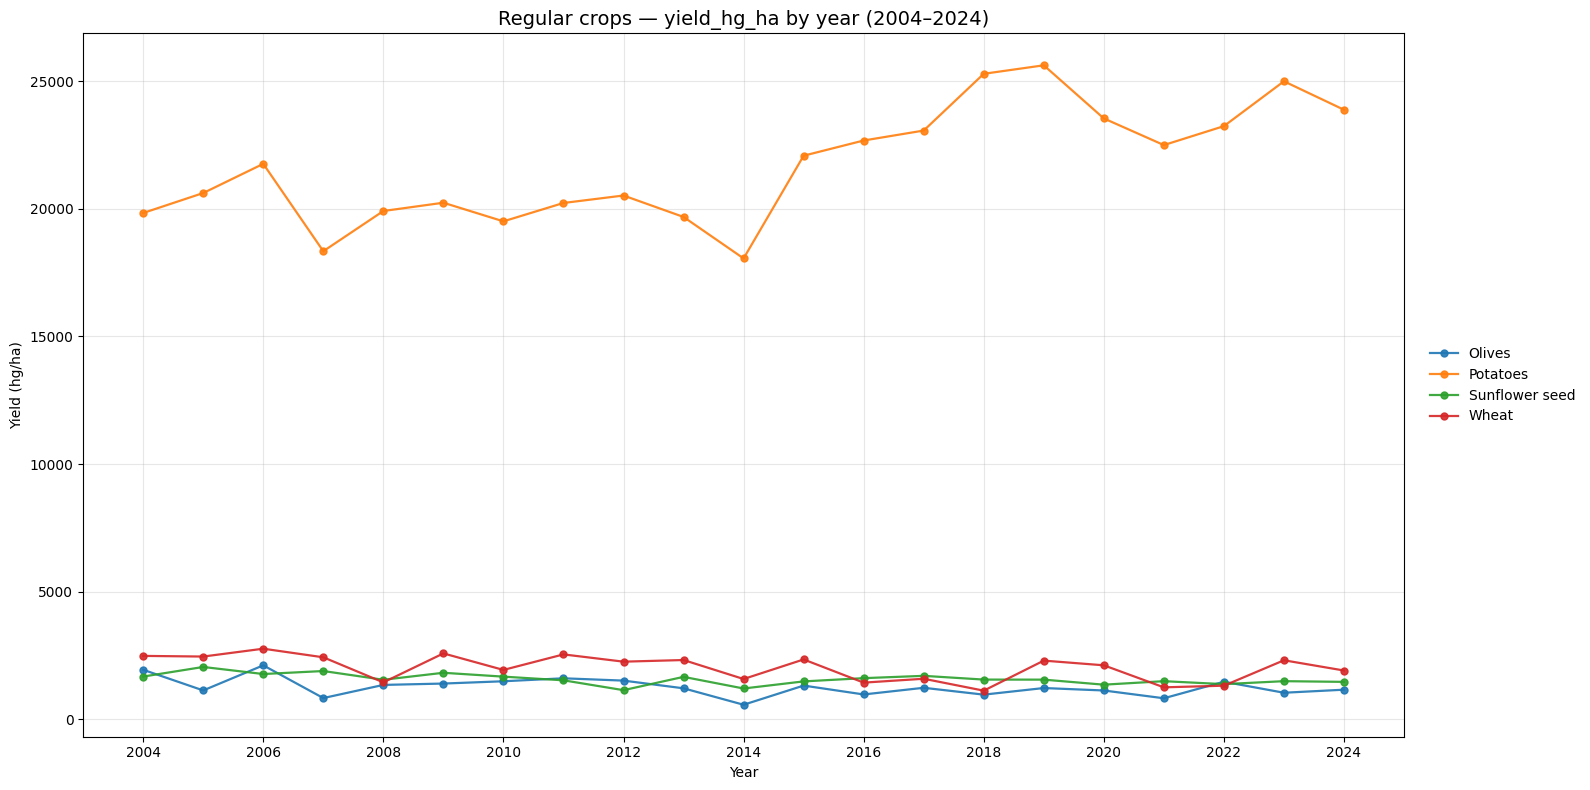

In [23]:
crops_list = sorted(fao_filtered["crop"].unique())

fig, ax = plt.subplots(figsize=(16, 8))

cmap = plt.get_cmap("tab10")
for i, crop in enumerate(crops_list):
    sub = fao_filtered[fao_filtered["crop"] == crop].sort_values("year")
    ax.plot(sub["year"], sub[TARGET],
            marker="o", markersize=5, linewidth=1.6,
            color=cmap(i % 10), label=crop, alpha=0.9)

ax.set_title(
    f"Regular crops — {TARGET} by year ({YEAR_START}–{YEAR_END})",
    fontsize=14,
)
ax.set_xlabel("Year")
ax.set_ylabel("Yield (hg/ha)")
ax.grid(True, alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5),
          fontsize=10, ncol=1, frameon=False)

# Force integer year ticks (avoid 2005.0, 2006.5, …)
ax.set_xticks(range(YEAR_START, YEAR_END + 1, 2))

plt.tight_layout()
plt.show()